# Hypothesis Testing
**Jiayi (Joyce) Qi**

We test whether short-sleep prevalence differs by **physical activity, income, and education**, using 5,000 random permutations per comparison. We report unweighted sample tests and separate survey-weighted descriptive summaries.

**Analysis scope.** We reuse the full cleaned analysis sample, including all prepared train/validation/test partitions, for consistency with the team's data pipeline. Preparation removed 3,005 education/activity-incomplete records (0.70% of otherwise eligible records). This may introduce selection bias. Income Unknown responses are additionally excluded from the income test only. Results from this analysis do not guide model tuning or feature selection using held-out outcomes.

All three tests concern unadjusted associations in the retained sample, not causal effects or survey-design-based national significance.

## 1. Data and reproducibility
Read `brfss_2022_clean.csv` without changing it. In Colab, use the same shared Drive location as the preparation notebook.

In [12]:
from pathlib import Path
from itertools import combinations, product
from collections import Counter
from math import comb
from importlib.metadata import version
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import beta, chi2_contingency

B = 5_000
SEED = 42
CHECK_SEEDS = (123, 2026)
ALPHA = 0.05

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 95)
plt.rcParams.update({
    "figure.dpi": 120, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, GREEN, GRAY = "#39779E", "#267B65", "#999999"

PROJECT_DIR = Path.cwd()
try:
    from google.colab import drive
except ImportError:
    data_directories = [
        PROJECT_DIR,
        PROJECT_DIR / "Data_preprocessing",
        PROJECT_DIR.parent / "Data_preprocessing",
    ]
else:
    drive.mount("/content/drive")
    PROJECT_DIR = Path(
        "/content/drive/Shareddrives/CIS5450 Final Project/Data_Cleaning"
    )
    data_directories = [PROJECT_DIR]

DATA_FILE = next(
    (folder / "brfss_2022_clean.csv" for folder in data_directories
     if (folder / "brfss_2022_clean.csv").is_file()), None
)
if DATA_FILE is None:
    raise FileNotFoundError(
        "Could not find brfss_2022_clean.csv. Check the data folder or update PROJECT_DIR."
    )

data = pd.read_csv(DATA_FILE, dtype={
    "physical_activity": "string", "income_group": "string",
    "education_level": "string", "state": "string",
})
required = {
    "sleep_hours", "enough_sleep", "physical_activity", "income_group",
    "education_level", "state", "survey_weight", "stratum_id", "psu_id",
}
if not required.issubset(data.columns):
    raise ValueError(f"Required columns missing: {sorted(required - set(data.columns))}")

states_and_dc = set(
    "AL AK AZ AR CA CO CT DE DC FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN "
    "MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY".split()
)
assert data["state"].isin(states_and_dc).all(), "Unexpected geographic scope."
assert data["sleep_hours"].isin(range(1, 25)).all(), "Invalid sleep duration."
assert data["enough_sleep"].isin([0, 1]).all(), "Invalid outcome coding."
assert data["enough_sleep"].eq(data["sleep_hours"].ge(7).astype(int)).all()
assert np.isfinite(data["survey_weight"]).all() and data["survey_weight"].gt(0).all()
for column in ["stratum_id", "psu_id"]:
    assert np.isfinite(data[column]).all() and data[column].gt(0).all()
    assert data[column].mod(1).eq(0).all(), "Invalid survey-design ID."
assert data["physical_activity"].isin(["1", "2"]).all(), "Expected cleaned activity responses."
assert data["education_level"].isin([str(i) for i in range(1, 7)]).all()
assert data["income_group"].isin([str(i) for i in range(1, 12)] + ["Unknown"]).all()

data["short_sleep"] = 1 - data["enough_sleep"]
print(f"Loaded {len(data):,} cleaned respondents; the source CSV is unchanged.")
if "split" in data:
    assert data["split"].isin(["train", "validation", "test"]).all()
    display(data["split"].value_counts().rename_axis("prepared_partition").to_frame("respondents"))
display(pd.DataFrame({
    "package": ["Python", "NumPy", "pandas", "SciPy", "Matplotlib"],
    "version": [sys.version.split()[0]] + [version(p) for p in ["numpy", "pandas", "scipy", "matplotlib"]],
}))
print(f"Primary seed: {SEED}; permutations per test: {B:,}; family alpha: {ALPHA}.")

Loaded 427,573 cleaned respondents; the source CSV is unchanged.


,respondents
prepared_partition,
train,256605
validation,85485
test,85483


,package,version
0,Python,3.11.16
1,NumPy,2.4.6
2,pandas,3.0.5
3,SciPy,1.17.1
4,Matplotlib,3.11.1


Primary seed: 42; permutations per test: 5,000; family alpha: 0.05.


## 2. Hypotheses and samples
`short_sleep = 1` means 1–6 hours; `0` means 7–24 hours, not necessarily healthy sleep.

| Comparison | Null hypothesis | Alternative | Statistic |
|---|---|---|---|
| Activity | Active and inactive groups have equal short-sleep proportions | The proportions differ | $T=\hat p_A-\hat p_N$ (two-sided) |
| Income | All 11 valid income groups have equal proportions | At least one differs | Pearson $\chi^2$ (large values are extreme) |
| Education | All 6 education groups have equal proportions | At least one differs | Pearson $\chi^2$ (large values are extreme) |

Each test uses the full cleaned sample with a valid response for its own grouping variable. Income Unknown is not treated as an income level. Sample sizes and exclusions below refer to the **cleaned base sample**, not the original survey.

In [13]:
specs = [
    {"name": "Activity", "column": "physical_activity", "kind": "difference",
     "labels": {"1": "Any activity", "2": "No activity"}},
    {"name": "Income", "column": "income_group", "kind": "chi_square",
     "labels": dict(zip([str(i) for i in range(1, 12)], [
         "< $10k", "$10k–<15k", "$15k–<20k", "$20k–<25k", "$25k–<35k",
         "$35k–<50k", "$50k–<75k", "$75k–<100k", "$100k–<150k",
         "$150k–<200k", "$200k+",
     ]))},
    {"name": "Education", "column": "education_level", "kind": "chi_square",
     "labels": dict(zip([str(i) for i in range(1, 7)], [
         "No school/kindergarten", "Grades 1–8", "Grades 9–11",
         "Grade 12/GED", "Some college/technical", "College graduate",
     ]))},
]

def group_summary(frame, spec):
    column = spec["column"]
    eligible = frame[column].isin(spec["labels"])
    sample = frame.loc[eligible, [column, "short_sleep", "survey_weight"]].copy()
    sample["weighted_short"] = sample["survey_weight"] * sample["short_sleep"]
    table = sample.groupby(column).agg(
        respondents=("short_sleep", "size"),
        short_sleepers=("short_sleep", "sum"),
        total_weight=("survey_weight", "sum"),
        short_weight=("weighted_short", "sum"),
    ).reindex(list(spec["labels"]))
    if table["respondents"].isna().any() or table["respondents"].le(0).any():
        raise ValueError(f"An expected {spec['name']} group is empty.")
    table["sample_percent"] = table["short_sleepers"] / table["respondents"] * 100
    table["weighted_percent"] = table["short_weight"] / table["total_weight"] * 100
    table.index = [spec["labels"][level] for level in table.index]
    table.index.name = "group"
    return table, int((~eligible).sum())

group_tables = {}
eligibility = []
for spec in specs:
    table, excluded = group_summary(data, spec)
    group_tables[spec["name"]] = table
    eligibility.append({
        "comparison": spec["name"], "cleaned_base_n": len(data),
        "excluded_invalid_or_unknown_group": excluded,
        "eligible_n": int(table["respondents"].sum()), "groups": len(table),
    })
display(pd.DataFrame(eligibility))

,comparison,cleaned_base_n,excluded_invalid_or_unknown_group,eligible_n,groups
0,Activity,427573,0,427573,2
1,Income,427573,89873,337700,11
2,Education,427573,0,427573,6


## 3. Permutation method
Under the working null, group labels are exchangeable with respect to short sleep. We fix group sizes and the total number of short sleepers. Drawing their allocation from a **multivariate hypergeometric distribution** produces the same unrestricted label-permutation distribution efficiently; the two-group case is hypergeometric.

For $B=5{,}000$, the Monte Carlo p-value is $(1+k)/(B+1)$. Here $k$ counts $|T_b|\geq|T_{obs}|$ for activity and $T_b\geq T_{obs}$ for income/education. The latter use simulated, not theoretical chi-square tails.

We report a 95% Clopper–Pearson interval for the simulated tail probability from $k/B$. This measures **Monte Carlo uncertainty**, not uncertainty in the population effect. Zero exceedances do not imply zero probability. Holm adjustment controls multiplicity across the three tests under their assumed-valid p-values; it does not fix survey-design limitations.

In [16]:
def statistic_from_counts(short_counts, group_sizes, kind):
    counts = np.asarray(short_counts, dtype=float)
    sizes = np.asarray(group_sizes, dtype=float)
    if kind == "difference":
        return counts[..., 0] / sizes[0] - counts[..., 1] / sizes[1]
    if kind != "chi_square":
        raise ValueError("Unknown statistic.")
    prevalence = counts.sum(axis=-1, keepdims=True) / sizes.sum()
    if np.any((prevalence <= 0) | (prevalence >= 1)):
        raise ValueError("Both outcome classes are required.")
    # Equivalent to Pearson chi-square for the full groups x 2 table.
    return ((counts - sizes * prevalence) ** 2 /
            (sizes * prevalence * (1 - prevalence))).sum(axis=-1)


def extreme_mask(null_statistics, observed, kind):
    threshold = abs(observed) if kind == "difference" else observed
    values = np.abs(null_statistics) if kind == "difference" else null_statistics
    tolerance = max(1e-14, abs(threshold) * 1e-14)
    return values >= threshold - tolerance


def tail_interval(k, b, confidence=0.95):
    tail = (1 - confidence) / 2
    lower = 0.0 if k == 0 else beta.ppf(tail, k, b - k + 1)
    upper = 1.0 if k == b else beta.ppf(1 - tail, k + 1, b - k)
    return float(lower), float(upper)


def holm_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(
        1, np.maximum.accumulate(p_values[order] * (len(p_values) - np.arange(len(p_values))))
    )
    return adjusted


def simulate_test(short_counts, group_sizes, kind, rng, b=B):
    sizes = np.asarray(group_sizes, dtype=np.int64)
    counts = np.asarray(short_counts, dtype=np.int64)
    assert np.all((0 <= counts) & (counts <= sizes)) and np.all(sizes > 0)
    observed = float(statistic_from_counts(counts, sizes, kind))
    draws = rng.multivariate_hypergeometric(
        sizes, int(counts.sum()), size=b, method="marginals"
    )
    assert np.all(draws.sum(axis=1) == counts.sum())
    assert np.all((draws >= 0) & (draws <= sizes))
    null = statistic_from_counts(draws, sizes, kind)
    k = int(extreme_mask(null, observed, kind).sum())
    low, high = tail_interval(k, b)
    return {
        "observed": observed, "null": null, "exceedances": k,
        "p_value": (k + 1) / (b + 1), "mc_low": low, "mc_high": high,
    }

In [15]:
def run_family(seed):
    # Independent reproducible streams; their order follows the hypothesis table.
    streams = np.random.SeedSequence(seed).spawn(len(specs))
    family = {}
    for spec, stream in zip(specs, streams):
        table = group_tables[spec["name"]]
        family[spec["name"]] = simulate_test(
            table["short_sleepers"].to_numpy(dtype=np.int64),
            table["respondents"].to_numpy(dtype=np.int64),
            spec["kind"], np.random.default_rng(stream),
        )
    return family

results = run_family(SEED)


def plot_comparison(spec):
    table = group_tables[spec["name"]]
    result = results[spec["name"]]
    observed, null = result["observed"], result["null"]
    activity = spec["kind"] == "difference"
    scale = 100 if activity else 1
    values, observed_display = null * scale, observed * scale
    fig, axes = plt.subplots(1, 2, figsize=(13, max(4.6, len(table) * 0.42)),
                             layout="constrained")
    y = np.arange(len(table))
    for offset, column, label, color in [
        (-0.18, "sample_percent", "Sample", BLUE),
        (0.18, "weighted_percent", "Survey-weighted", GREEN),
    ]:
        axes[0].barh(y + offset, table[column], height=0.34, label=label, color=color)
    axes[0].set(yticks=y, yticklabels=table.index, xlim=(0, 100),
                xlabel="Short-sleep prevalence (%)", title="Group descriptions")
    axes[0].invert_yaxis()
    axes[0].legend(frameon=False, fontsize=9)
    ax = axes[1]
    ax.hist(values, bins=40, color=BLUE, alpha=0.85)
    bounds = [observed_display, -observed_display] if activity else [observed_display]
    left, right = ax.get_xlim()
    for position in sorted(set(bounds)):
        if left <= position <= right:
            ax.axvline(position, color="#A84432", linestyle="--")
    ax.set(xlim=(left, right), ylabel="Simulations", title="Permutation null (zoom)",
           xlabel="Active − inactive (percentage points)" if activity else "Pearson chi-square")
    ax.text(0.02, 0.96,
            f"Observed = {observed_display:.3f}" + (" pp" if activity else "") +
            f"\nExtreme draws: {result['exceedances']:,}/{B:,}" +
            f"\nMonte Carlo p = {result['p_value']:.6f}",
            transform=ax.transAxes, va="top", fontsize=9,
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9})
    # The overview explicitly marks observed values even when far beyond the null.
    inset = ax.inset_axes([0.51, 0.53, 0.46, 0.39])
    inset.hist(values, bins=30, color=GRAY)
    for position in sorted(set(bounds)):
        inset.axvline(position, color="#A84432", linestyle="--", linewidth=1.2)
    inset.set_title("Full range + observed", fontsize=8)
    inset.tick_params(labelsize=7)
    inset.set_yticks([])
    fig.suptitle(f"{spec['name']}: short sleep and simulated null | cleaned analysis sample", fontsize=13)
    plt.show()
    plt.close(fig)


def show_comparison(name):
    spec = next(s for s in specs if s["name"] == name)
    table = group_tables[name]
    result = results[name]
    display(table[["respondents", "short_sleepers", "sample_percent", "weighted_percent"]].round(2))
    if spec["kind"] == "difference":
        weighted_gap = table["weighted_percent"].iloc[0] - table["weighted_percent"].iloc[1]
        print(f"Observed sample difference (active − inactive): {result['observed'] * 100:.2f} pp.")
        print(f"Separate weighted descriptive difference: {weighted_gap:.2f} pp (no permutation p-value attached).")
    else:
        v = np.sqrt(result["observed"] / table["respondents"].sum())
        sample_range = table["sample_percent"].max() - table["sample_percent"].min()
        print(f"Observed chi-square: {result['observed']:.3f}; unweighted Cramér's V: {v:.4f}.")
        print(f"Highest − lowest sample prevalence: {sample_range:.2f} pp (descriptive, not a pairwise test).")
    print(f"Monte Carlo p: {result['p_value']:.6f}; extreme draws: {result['exceedances']:,}/{B:,}.")
    print(f"95% Monte Carlo tail-probability interval: [{result['mc_low']:.6f}, {result['mc_high']:.6f}].")
    plot_comparison(spec)

## 4. Activity: two-sided proportion difference
A negative statistic means less short sleep in the active group. The weighted difference is descriptive and does not inherit the unweighted permutation p-value. This comparison is not adjusted for age, employment, health, or other factors.

,respondents,short_sleepers,sample_percent,weighted_percent
group,,,,
Any activity,327231,101161,30.91,34.55
No activity,100342,38512,38.38,40.95


Observed sample difference (active − inactive): -7.47 pp.
Separate weighted descriptive difference: -6.41 pp (no permutation p-value attached).
Monte Carlo p: 0.000200; extreme draws: 0/5,000.
95% Monte Carlo tail-probability interval: [0.000000, 0.000738].


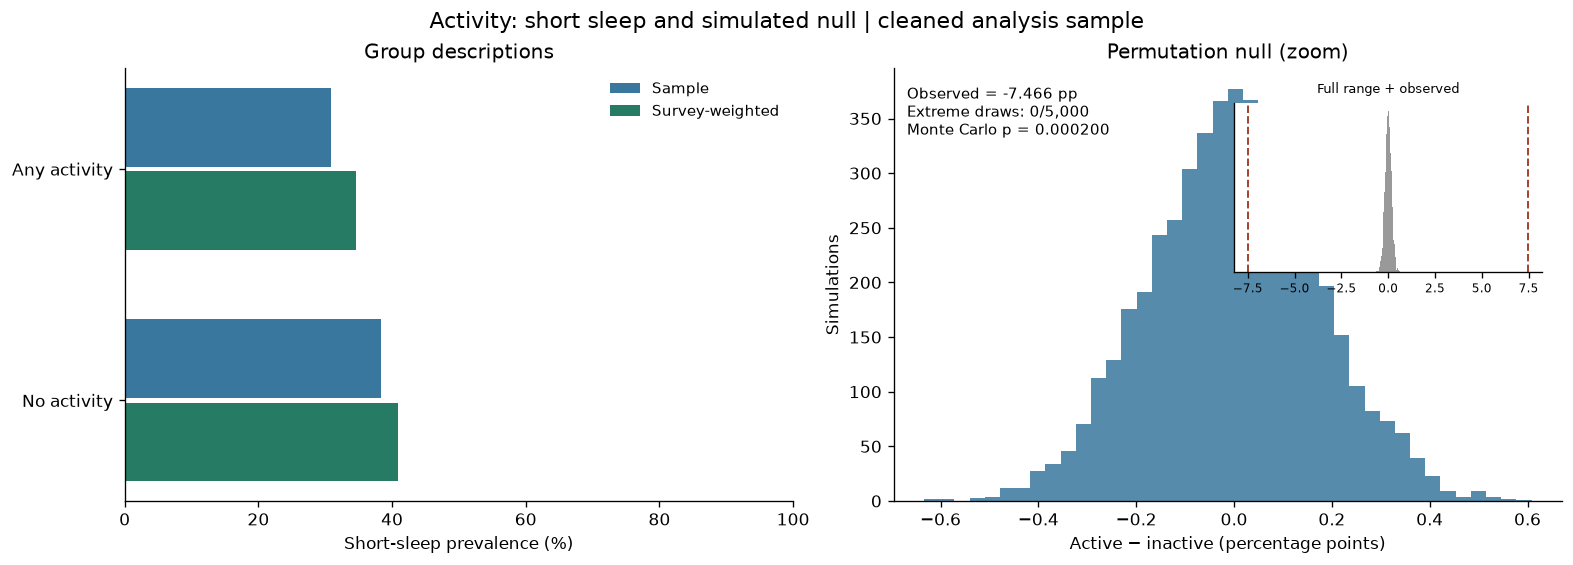

In [17]:
show_comparison("Activity")

## 5. Income: overall group comparison
Test all 11 valid income categories together, excluding Income Unknown. Rejection indicates some group difference, not a monotonic trend or a significant difference between every pair. Income nonresponse limits interpretation.

,respondents,short_sleepers,sample_percent,weighted_percent
group,,,,
< $10k,9033,3896,43.13,41.90
$10k–<15k,9977,4190,42.00,42.46
$15k–<20k,13103,5195,39.65,40.79
$20k–<25k,19098,7265,38.04,38.99
$25k–<35k,40571,14661,36.14,39.18
$35k–<50k,45239,15391,34.02,38.10
$50k–<75k,57872,18790,32.47,37.16
$75k–<100k,47651,14716,30.88,35.87
$100k–<150k,49624,14946,30.12,34.48


Observed chi-square: 2312.068; unweighted Cramér's V: 0.0827.
Highest − lowest sample prevalence: 16.31 pp (descriptive, not a pairwise test).
Monte Carlo p: 0.000200; extreme draws: 0/5,000.
95% Monte Carlo tail-probability interval: [0.000000, 0.000738].


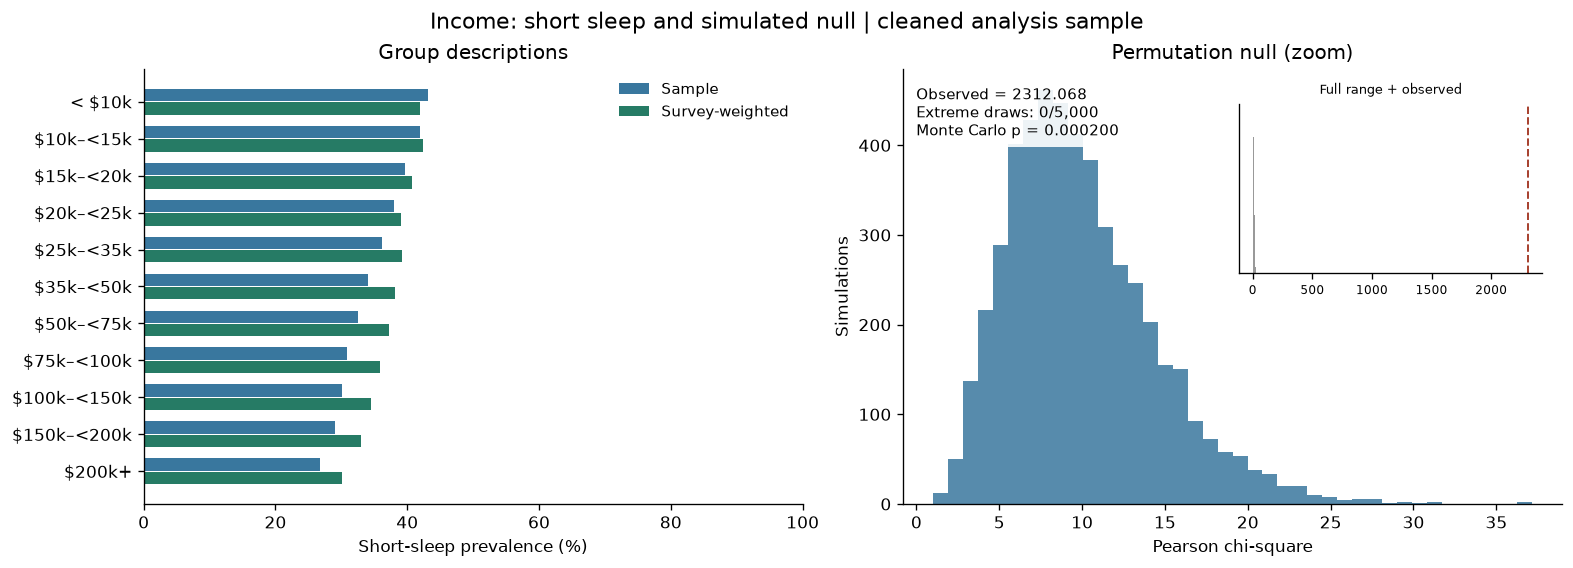

In [18]:
show_comparison("Income")

## 6. Education: overall group comparison
Test the six education categories together. Read rates alongside their group sizes, especially the smallest category. No post-hoc pairwise tests are included.

,respondents,short_sleepers,sample_percent,weighted_percent
group,,,,
No school/kindergarten,619,203,32.79,29.37
Grades 1–8,7507,2536,33.78,31.88
Grades 9–11,15826,6382,40.33,40.41
Grade 12/GED,104393,37931,36.33,38.22
Some college/technical,116367,41981,36.08,38.75
College graduate,182861,50640,27.69,31.01


Observed chi-square: 3736.461; unweighted Cramér's V: 0.0935.
Highest − lowest sample prevalence: 12.63 pp (descriptive, not a pairwise test).
Monte Carlo p: 0.000200; extreme draws: 0/5,000.
95% Monte Carlo tail-probability interval: [0.000000, 0.000738].


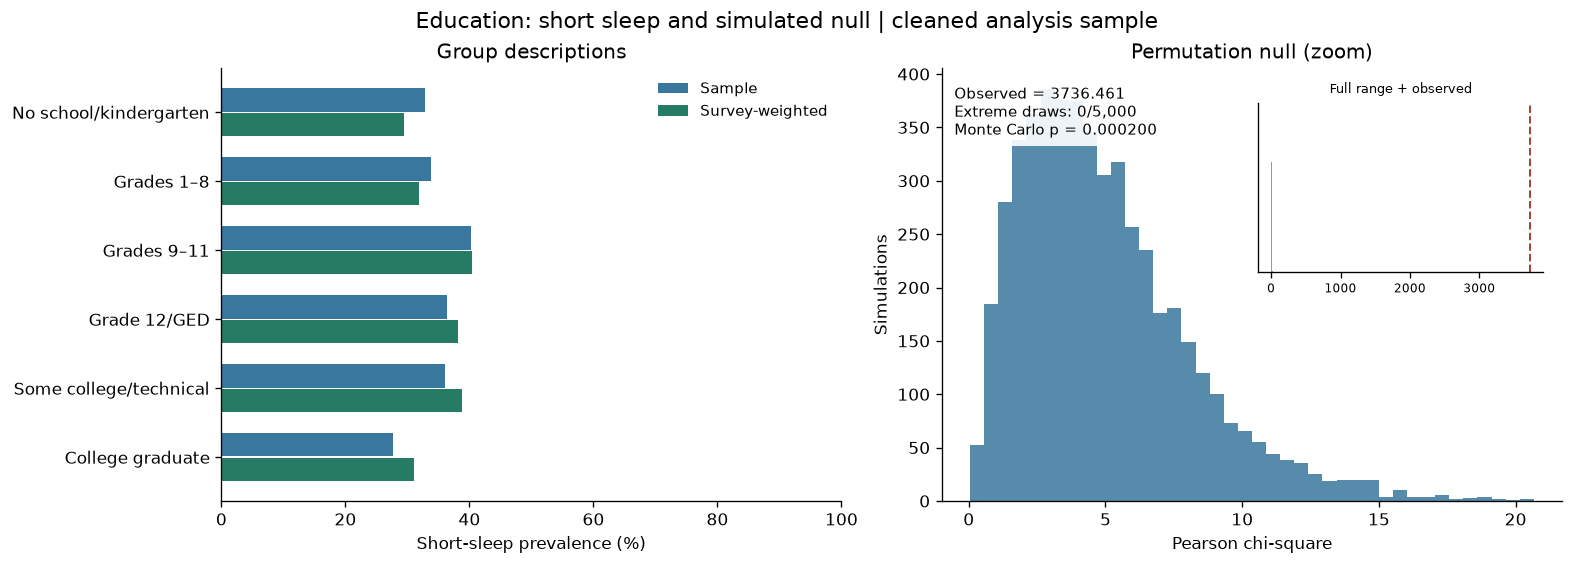

In [19]:
show_comparison("Education")

## 7. Joint results and simulation stability
Report raw and Holm-adjusted p-values for the three-test family. Repeat with two additional seeds using the same simulation budget; these checks do not replace the primary seed or select a more favorable p-value.

In [20]:
summary_rows = []
for spec in specs:
    name = spec["name"]
    table, result = group_tables[name], results[name]
    n = int(table["respondents"].sum())
    summary_rows.append({
        "comparison": name, "eligible_n": n,
        "statistic": "Sample difference (pp)" if spec["kind"] == "difference" else "Pearson chi-square",
        "observed": result["observed"] * (100 if spec["kind"] == "difference" else 1),
        "effect_size": (f"{result['observed'] * 100:.2f} pp" if spec["kind"] == "difference"
                        else f"V = {np.sqrt(result['observed'] / n):.4f}"),
        "extreme_draws": result["exceedances"], "p_raw": result["p_value"],
        "mc_tail_low": result["mc_low"], "mc_tail_high": result["mc_high"],
    })
summary = pd.DataFrame(summary_rows)
summary["p_holm"] = holm_adjust(summary["p_raw"])
summary["decision_at_0.05"] = np.where(summary["p_holm"] <= ALPHA, "Reject H0", "Do not reject H0")
display(summary.round(6))

stability_rows = []
for seed in (SEED,) + CHECK_SEEDS:
    family = results if seed == SEED else run_family(seed)
    adjusted = holm_adjust([family[s["name"]]["p_value"] for s in specs])
    for spec, p_holm in zip(specs, adjusted):
        result = family[spec["name"]]
        stability_rows.append({
            "seed": seed, "comparison": spec["name"],
            "extreme_draws": result["exceedances"], "p_raw": result["p_value"],
            "p_holm": p_holm, "reject_holm": p_holm <= ALPHA,
        })
stability = pd.DataFrame(stability_rows)
display(stability.round(6))
consistent = stability.groupby("comparison")["reject_holm"].nunique().eq(1).all()
print("Holm decisions agree across seeds." if consistent else
      "Some Holm decisions vary across seeds; Monte Carlo precision needs attention.")
print(f"Minimum reportable Monte Carlo p-value: {1 / (B + 1):.6f}; zero exceedances are not p = 0.")

,comparison,eligible_n,statistic,observed,effect_size,extreme_draws,p_raw,mc_tail_low,mc_tail_high,p_holm,decision_at_0.05
0,Activity,427573,Sample difference (pp),-7.466491,-7.47 pp,0,0.0002,0.0,0.000738,0.0006,Reject H0
1,Income,337700,Pearson chi-square,2312.068278,V = 0.0827,0,0.0002,0.0,0.000738,0.0006,Reject H0
2,Education,427573,Pearson chi-square,3736.461196,V = 0.0935,0,0.0002,0.0,0.000738,0.0006,Reject H0


,seed,comparison,extreme_draws,p_raw,p_holm,reject_holm
0,42,Activity,0,0.0002,0.0006,True
1,42,Income,0,0.0002,0.0006,True
2,42,Education,0,0.0002,0.0006,True
3,123,Activity,0,0.0002,0.0006,True
4,123,Income,0,0.0002,0.0006,True
5,123,Education,0,0.0002,0.0006,True
6,2026,Activity,0,0.0002,0.0006,True
7,2026,Income,0,0.0002,0.0006,True
8,2026,Education,0,0.0002,0.0006,True


Holm decisions agree across seeds.
Minimum reportable Monte Carlo p-value: 0.000200; zero exceedances are not p = 0.


## 8. Interpretation and limits
The computed conclusions below are summarized in two tables: what the tests show and how far those conclusions extend.


In [21]:
for row in summary.itertuples(index=False):
    if row.p_holm <= ALPHA:
        conclusion = "Evidence of an unadjusted association under the working permutation null"
    else:
        conclusion = "Insufficient evidence to reject equal proportions under the working permutation null"
    print(f"{row.comparison}: {conclusion}; Holm p = {row.p_holm:.6f}; {row.effect_size}.")

Activity: Evidence of an unadjusted association under the working permutation null; Holm p = 0.000600; -7.47 pp.
Income: Evidence of an unadjusted association under the working permutation null; Holm p = 0.000600; V = 0.0827.
Education: Evidence of an unadjusted association under the working permutation null; Holm p = 0.000600; V = 0.0935.


### Main findings

All three tests reject equal short-sleep proportions at family alpha = 0.05 after Holm correction (**adjusted p ≈ 0.000600 each**), under the sample-level exchangeability assumption.

| Comparison | Unweighted result | Interpretation |
|---|---|---|
| Activity | Active − inactive = **−7.47 percentage points** | Short sleep is less common in the active group. |
| Income | **Cramér’s V = 0.0827** | Some income groups differ; the overall association is modest. |
| Education | **Cramér’s V = 0.0935** | Some education groups differ; the overall association is modest. |

Statistical significance does not by itself imply a large or practically important difference. Weighted group rates are separate descriptive estimates; these p-values do not test them.

### Interpretation boundaries

| Issue | What it means for the conclusions |
|---|---|
| Survey design | Individual permutations ignore strata, PSU clustering, and unequal selection probabilities; these are not design-based national tests. |
| Sample selection | Results apply to the retained cleaned sample; income also excludes Unknown responses. Selection bias may remain. |
| Confounding | Comparisons are unadjusted: they do not establish causation, independent effects, or which income/education pairs differ. |
| Exploratory status | Activity was prespecified; income and education were added after EDA. |
| Simulation precision | Each test had **0/5,000 extreme draws**, giving raw p ≈ **0.000200**, not zero. The 95% Monte Carlo tail interval is **[0, 0.000738]**; all three seeds gave the same decisions. |

**Method reference:** [SciPy permutation-test documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html).
